# Background-relative beta-effect analysis

This notebook tests whether EAC anticyclonic eddies (AEs) have a northward/equatorward residual drift and cyclonic eddies (CEs) a southward/poleward residual drift after subtracting the strong southwestward background flow. It uses the cache produced by `build_background_cache.py`.

The primary sample has planetary PV-gradient magnitude greater than topographic PV-gradient magnitude. The topographic term uses $(w+f)\nabla h/h^2$, so the dominance mask is calculated separately for AEs and CEs.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
if not (HERE / 'background_flow_tools.py').exists():
    HERE = Path('MRes/seacofs_eddy_tilt_analysis/beta_effect_background_flow').resolve()
sys.path.insert(0, str(HERE))
sys.path.insert(0, str(HERE.parent))

import seacofs_tilt_tools as tilt
from background_flow_tools import BackgroundConfig, load_background_cache
from analysis_tools import (METHODS, add_track_velocity, add_residual_velocities,
                            propagation_summary, eddy_bootstrap_ci,
                            vorticity_budget_summary)
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Load eddies and polarity-specific PV-gradient terms

`topo_plan_ratio = log(|topographic PV gradient| / |planetary PV gradient|)`. Therefore values below zero identify planetary-dominant observations. Because the topographic numerator contains `w + f`, AE and CE masks need not select the same locations.

In [2]:
paths = tilt.Paths()
grid = tilt.load_grid(paths.grid, paths.z_r)
df, _ = tilt.load_tilt_tables(paths, add_regions=True, grid=grid)
df = tilt.add_pv_gradient_terms(df, grid)

primary = df.copy() 
# primary = df.loc[df['topo_plan_ratio'] < 0].copy()
# primary = df[df.Region.isin(['U1','U2','D1','D2'])].copy()
# primary = df[df.Region.isin(['S1','S2'])].copy()

pd.crosstab(primary['Cyc'], columns='observations').join(
    primary.groupby('Cyc')['Eddy'].nunique().rename('eddies'))

,observations,eddies
Cyc,,
AE,64952,1446
CE,62474,1536


## 2. Load the one-pass background cache

Run `01_build_background_cache.ipynb` first. Nine estimates are retained: instantaneous annulus, monthly climatological, and exact count-weighted full-archive backgrounds, each at the surface, thickness-weighted 0–200 m, and thickness-weighted 0–500 m. The full-archive fields are additional sensitivity tests, not replacements for the seasonally resolved estimates.

In [3]:
config = BackgroundConfig()
background = load_background_cache(config)
required_background = {'clim_200_east_ms', 'clim_200_north_ms',
                       'full_200_east_ms', 'full_200_north_ms',
                       'full_surface_east_ms', 'full_surface_north_ms',
                       'full_500_east_ms', 'full_500_north_ms'}
missing_background = required_background - set(background.columns)
if missing_background:
    raise RuntimeError('Run 01_build_background_cache.ipynb with the all-eddy v3 cache first.')
primary = primary.merge(background, on=['Eddy', 'Day'], how='inner', validate='one_to_one')
primary = add_track_velocity(primary, grid.angle, window=5)
primary = add_residual_velocities(primary)
print(f"Matched {len(primary):,} observations from {primary['Eddy'].nunique():,} eddies")

Matched 127,426 observations from 2,982 eddies


In [4]:
def xy_to_distance_direction(x, y):
    distance = np.hypot(x, y)
    direction = (np.degrees(np.arctan2(x, y)) + 360) % 360
    return distance, direction

def paired_rose(df_data, x, y, mag_bins=[0, 5, 10, 15, 20, 25, np.inf]): 

    mag, theta = xy_to_distance_direction(x, y)
    KM_DAY_TO_M_S = 1000.0 / 86400.0
    df_data['mag'] = mag / KM_DAY_TO_M_S
    df_data['theta'] = theta

    fig, axs = plt.subplots(1, 2, figsize=(12, 7), subplot_kw={"projection": "polar"}, constrained_layout=True)
    for ax, cyc, colors in zip(axs, ["AE", "CE"], [plt.cm.Reds(np.linspace(0.15, 1, len(mag_bins) - 1)), plt.cm.Blues(np.linspace(0.15, 1, len(mag_bins) - 1))]):
        subset = df_data.loc[df_data.Cyc == cyc].dropna(subset=["theta", "mag"])
        tilt.plot_windrose(ax, subset, title='', colors=colors, mag='mag', theta='theta', mag_bins=mag_bins)#, rlim=2300)# 
        ax.legend(title=f"{cyc}\n prop. (km/day)", loc="upper left", bbox_to_anchor=(1.05, 1.05), frameon=False)
    
        ax.text(-0.0, 1.02, 'a)' if cyc=='AE' else 'b)', transform=ax.transAxes,
                    fontsize=12, fontweight='bold', va='top', ha='left')
    # plt.suptitle('Off-shore')
    plt.show()
    return


ann_200


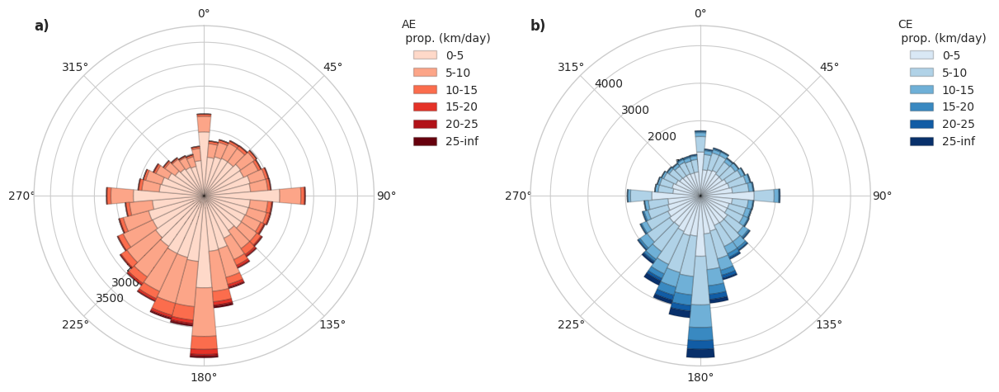

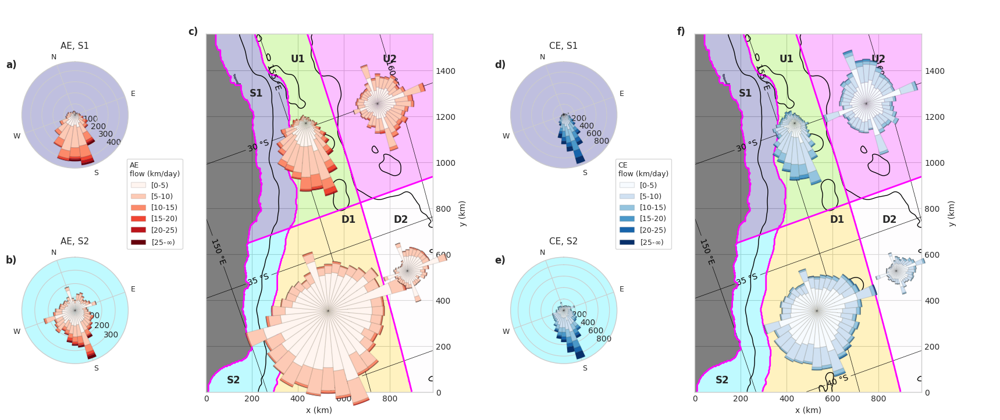

clim_200


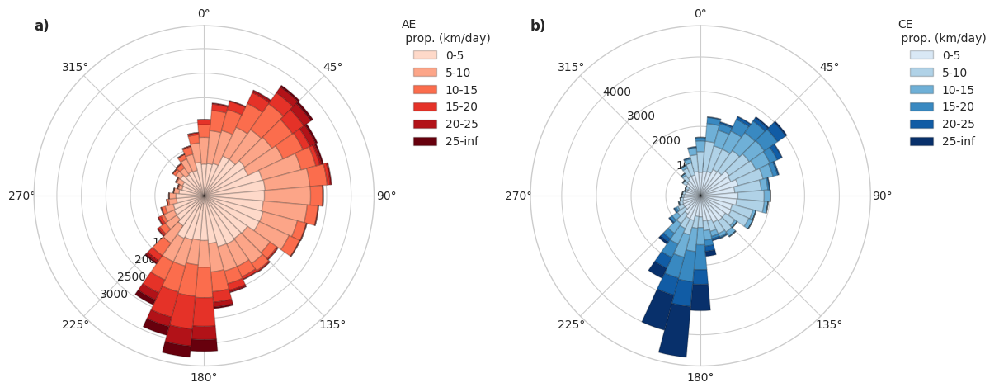

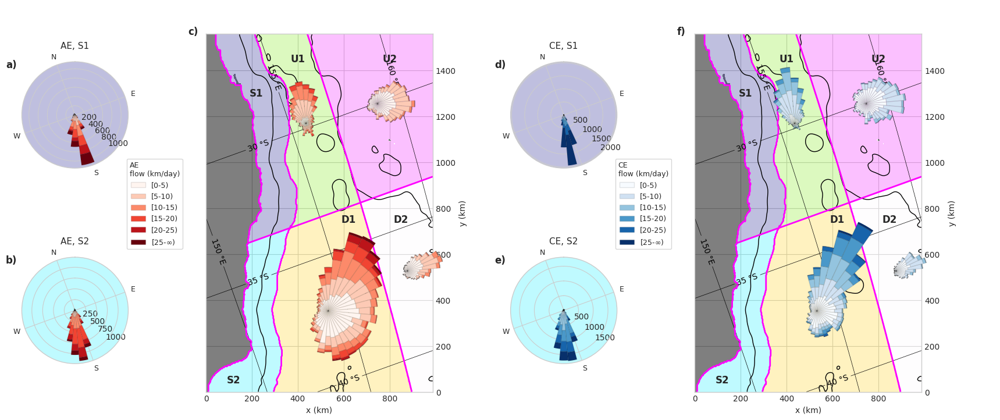

full_200


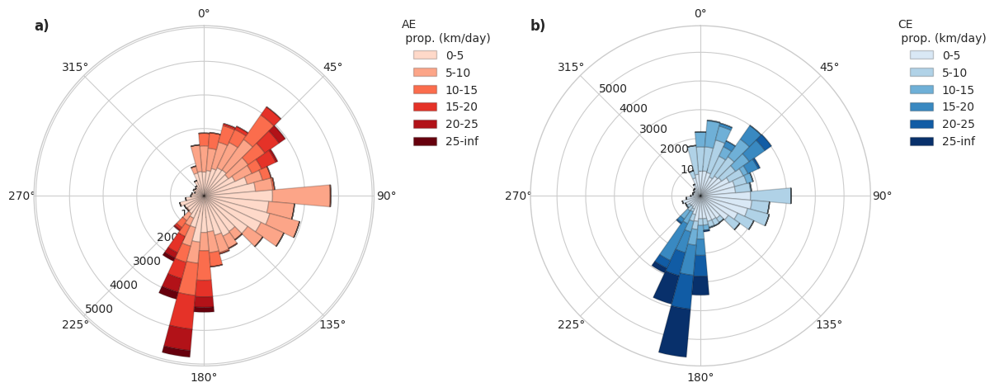

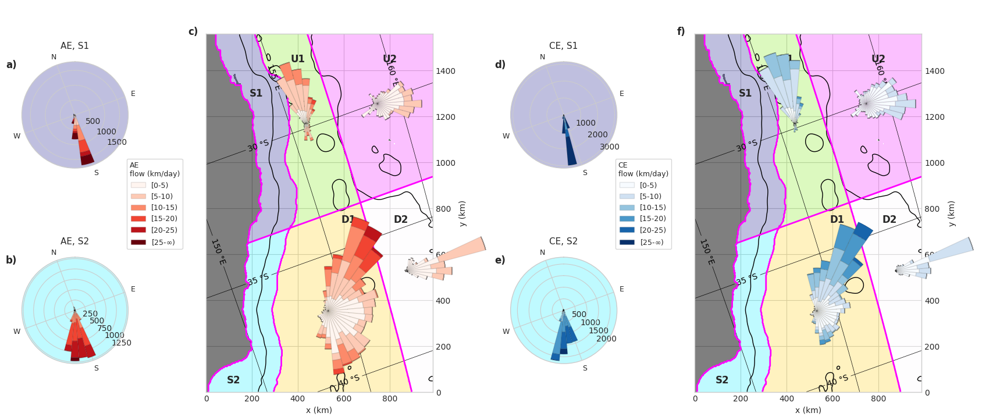

full_500


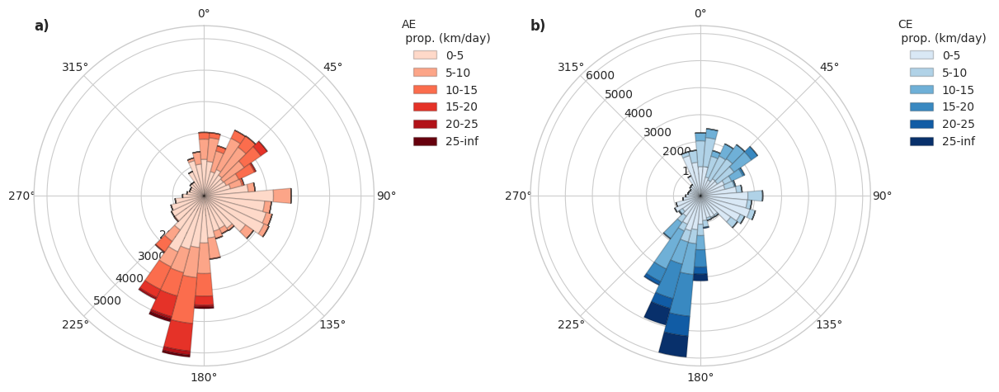

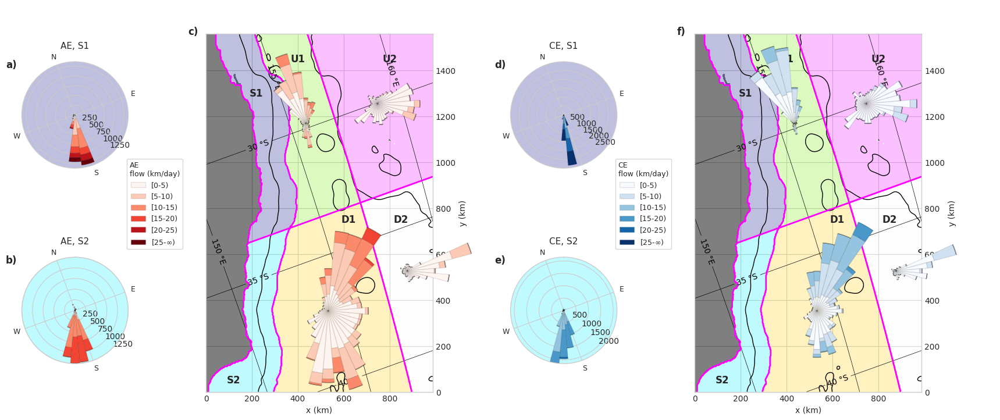

full_surface


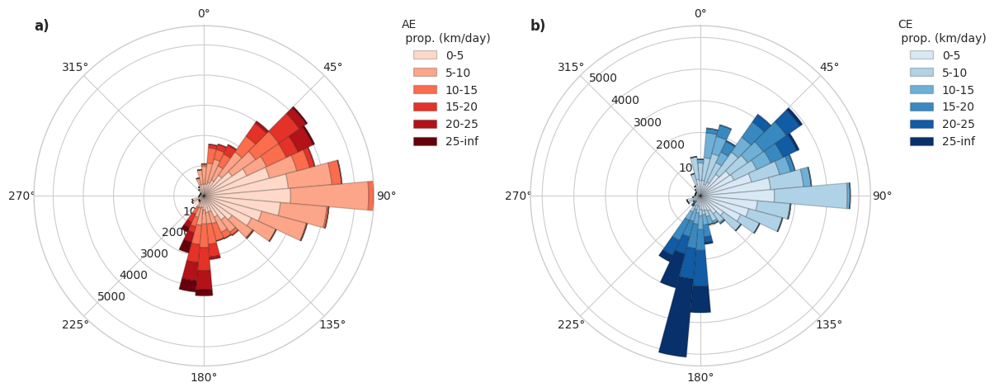

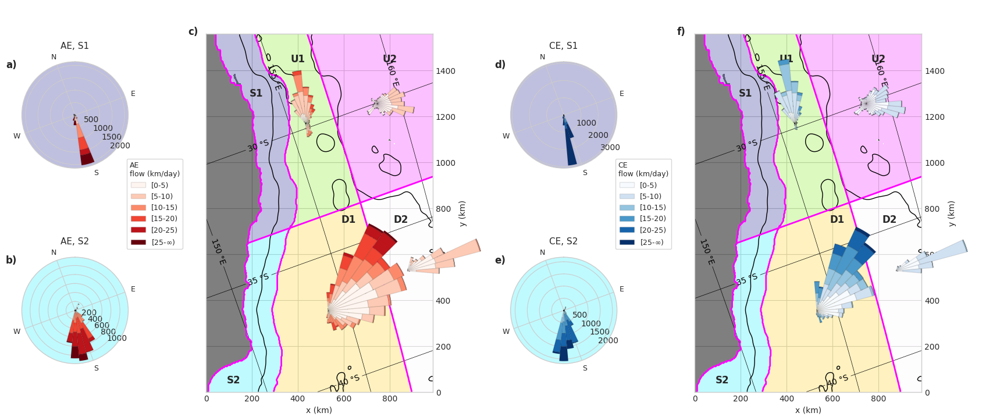

In [5]:
pairs = [
    (col, col.replace('_east_ms', '_north_ms'))
    for col in sorted(required_background)
    if '_east_ms' in col
]

for x_lab, y_lab in pairs:
    print(x_lab[:-8])

    x, y = primary[x_lab], primary[y_lab]
    paired_rose(primary.copy(), x, y)

    mag, theta = xy_to_distance_direction(x, y)
    KM_DAY_TO_M_S = 1000.0 / 86400.0
    df = primary.copy()
    df['mag'] = mag/KM_DAY_TO_M_S
    df['theta'] = theta
    # print(x_lab[:-8])
    tilt.rose_plot(df, grid=grid, mag='mag', theta='theta',
                   mag_bins=(0, 5, 10, 15, 20, 25, np.inf), legend_title='flow (km/day)')
    # tilt.rose_plot(df, grid=grid)

## 3. Residual meridional propagation

Track velocities are obtained with a time-aware position derivative and then smoothed with a centred five-observation rolling median. The rotated-grid `xc`, `yc` velocities are converted to true east/north using the ROMS grid angle. Confidence intervals resample whole eddies, not individual days. Evidence for beta drift is AE residual north velocity above zero and CE residual north velocity below zero, robust across background definitions.

ann_surface_residual


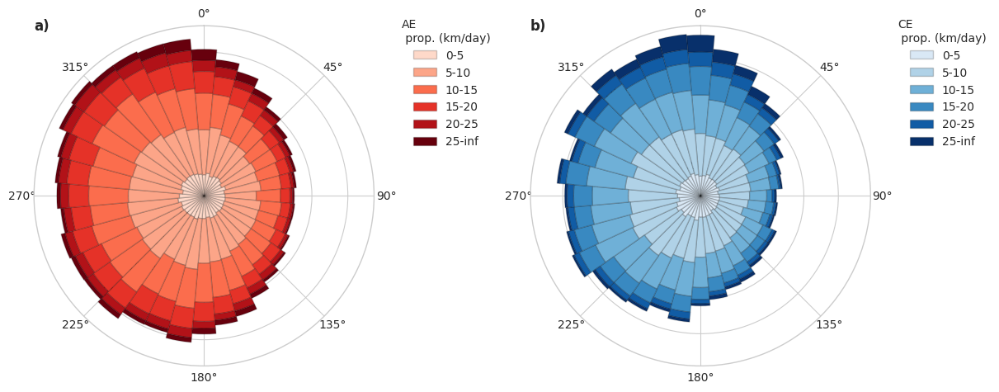

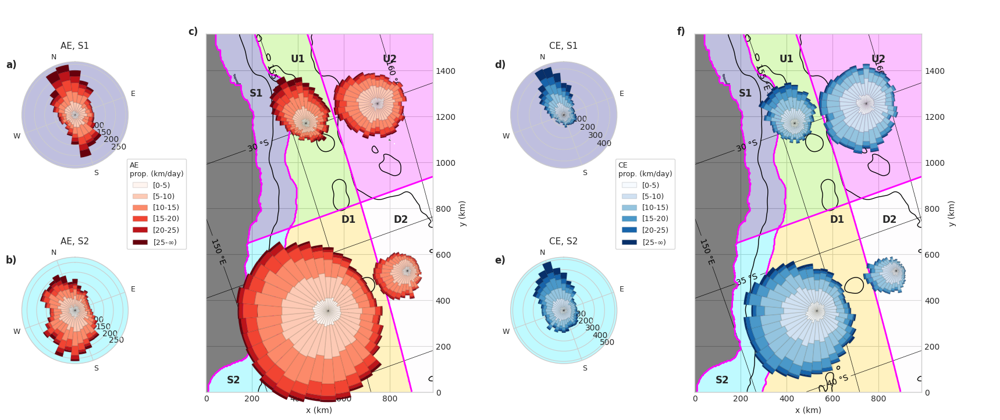

ann_200_residual


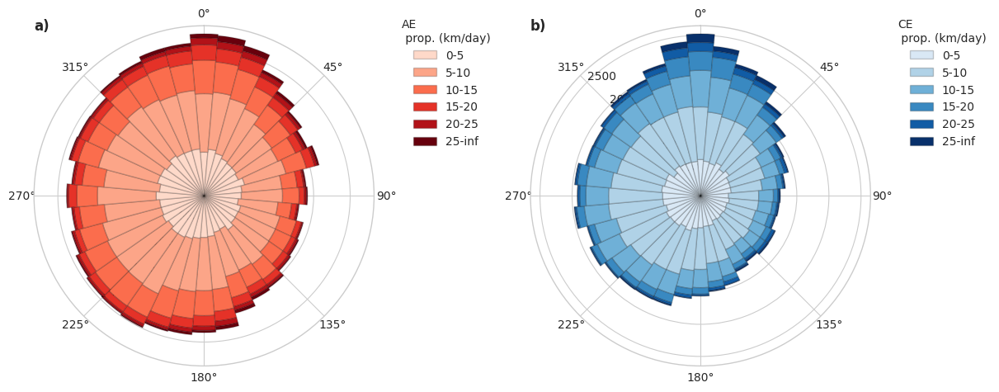

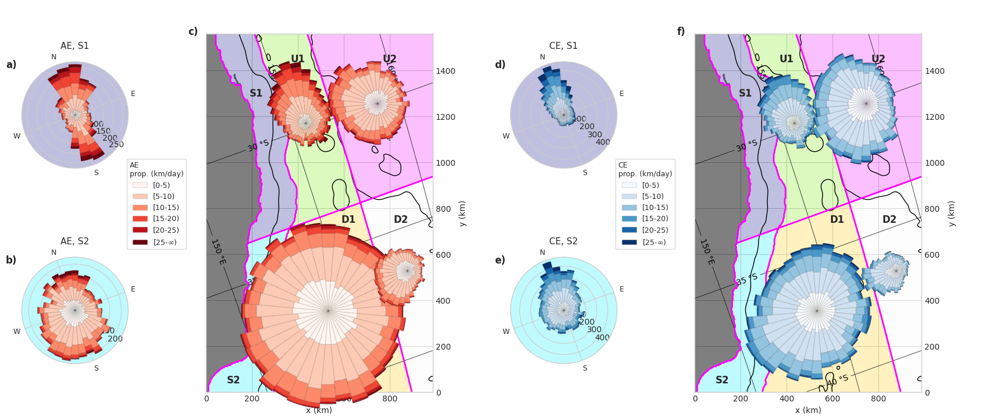

ann_500_residual


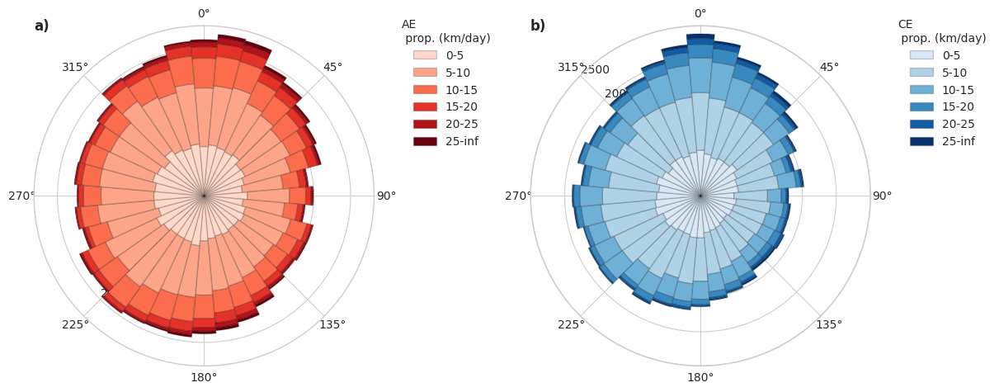

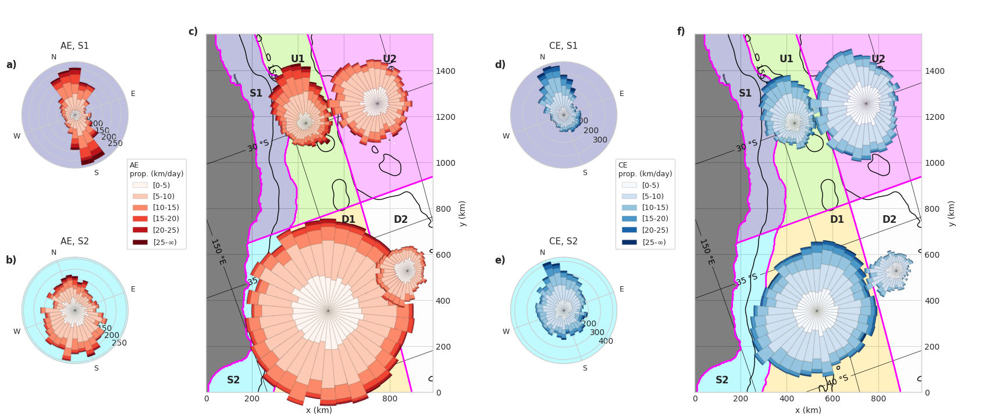

clim_surface_residual


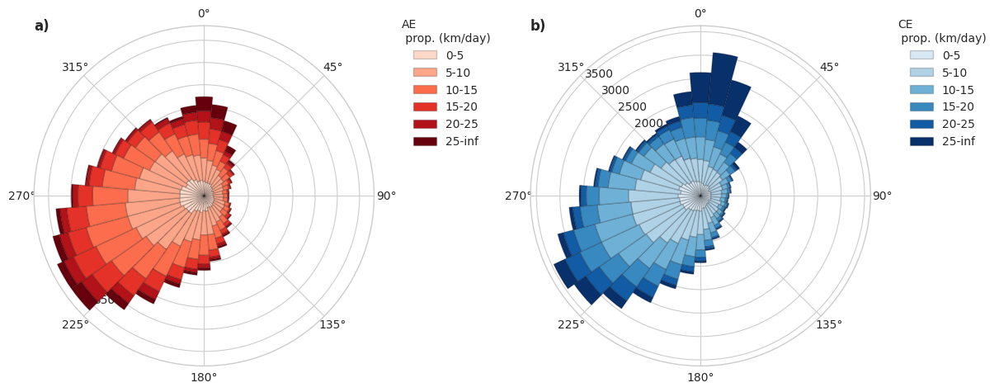

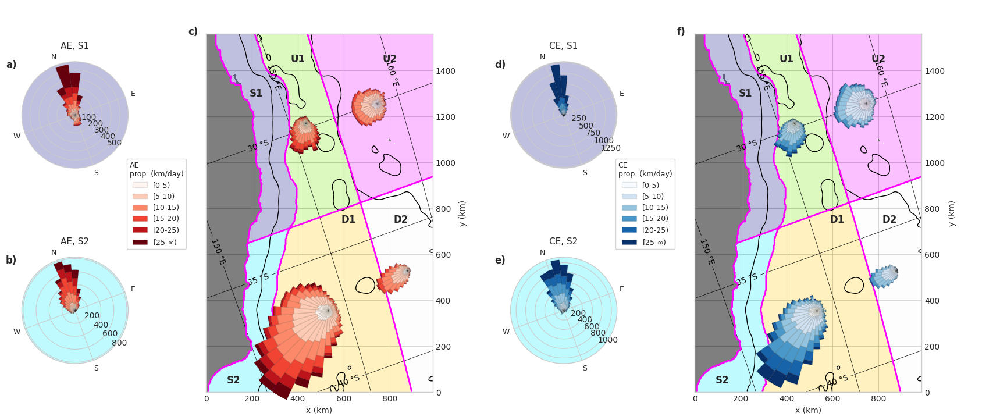

clim_200_residual


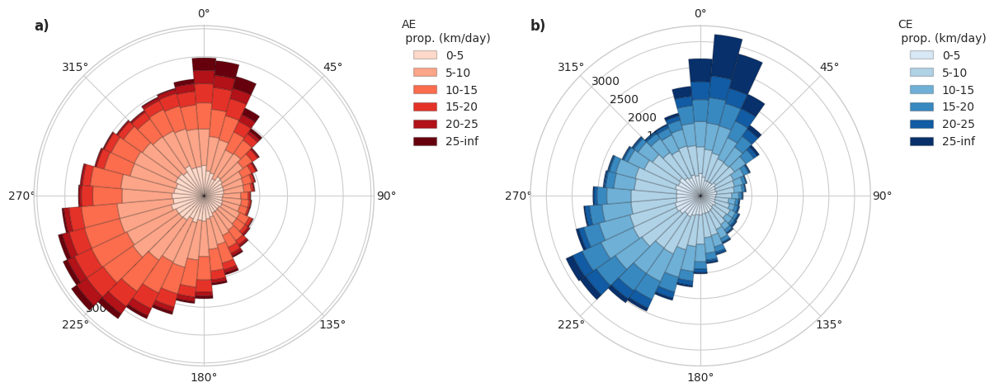

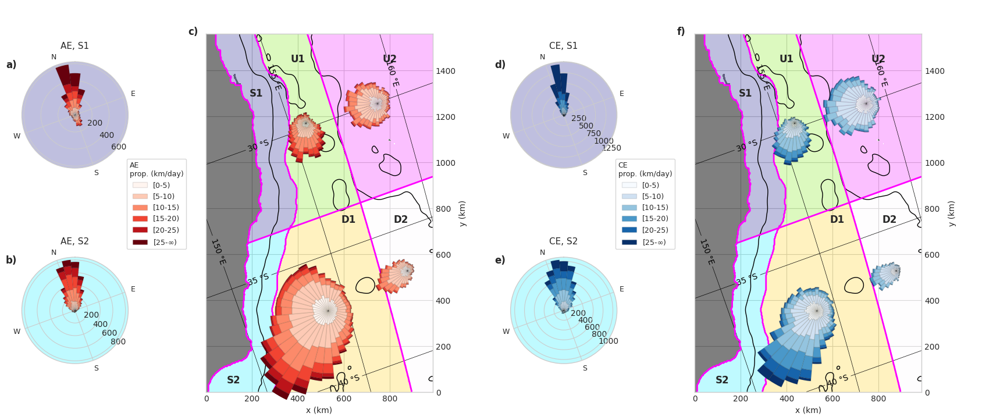

clim_500_residual


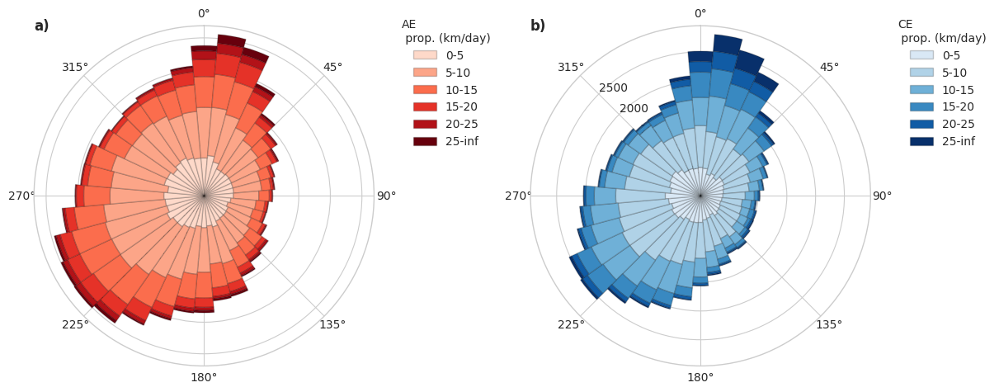

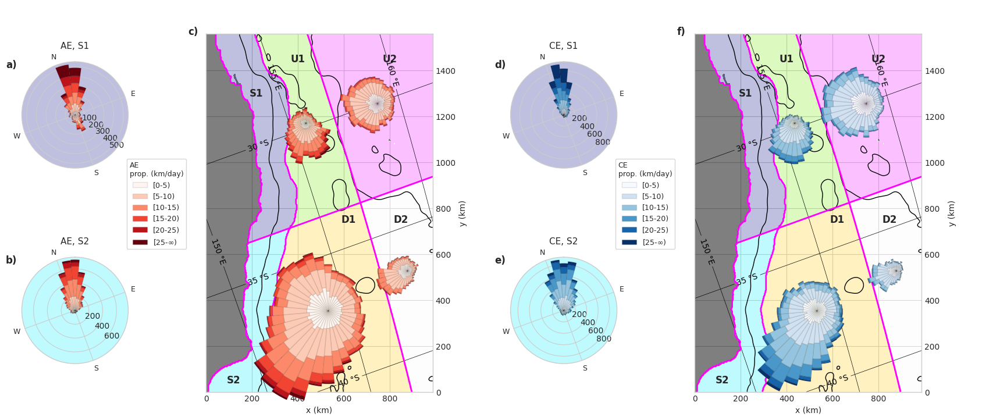

full_surface_residual


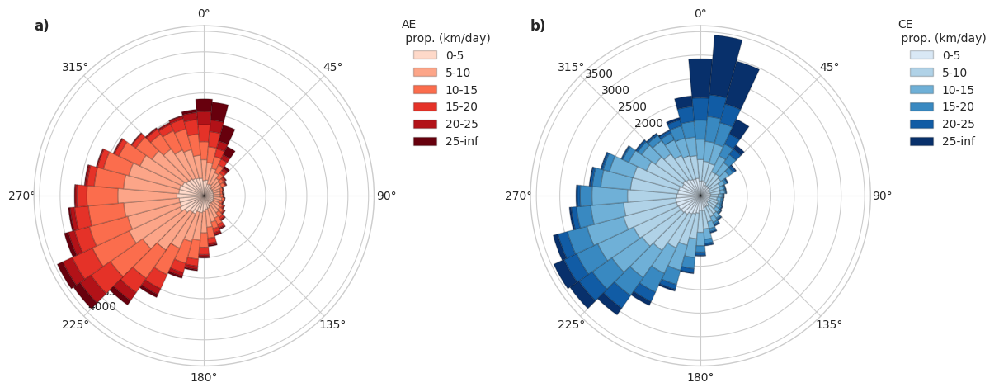

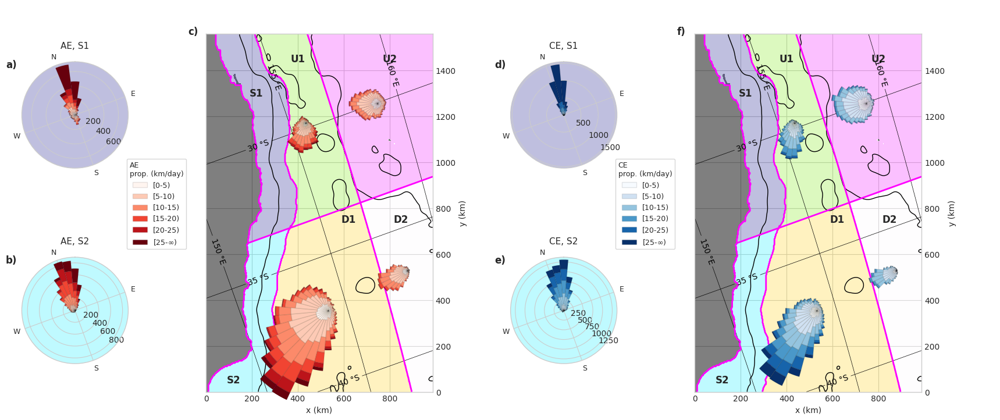

full_200_residual


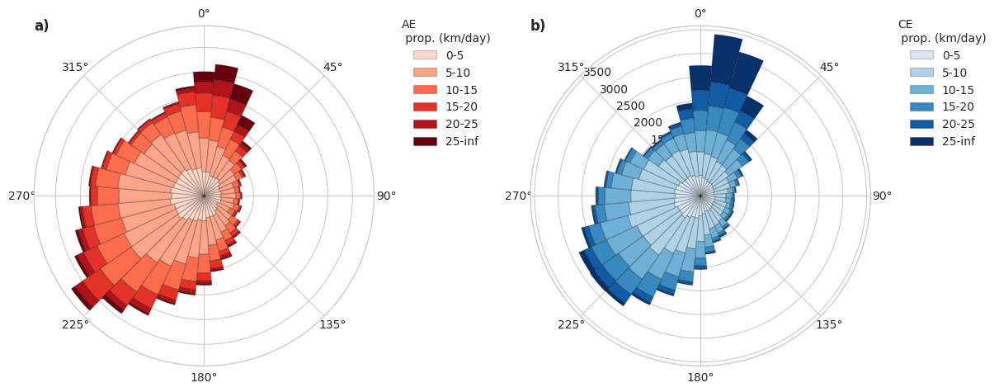

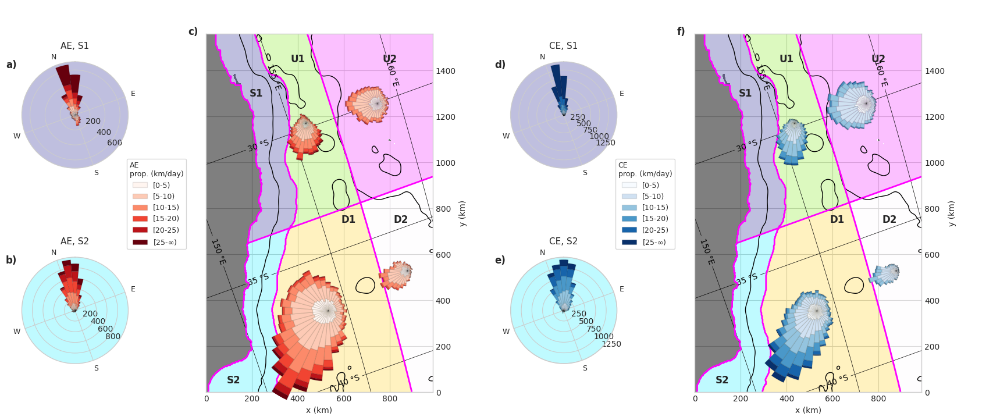

full_500_residual


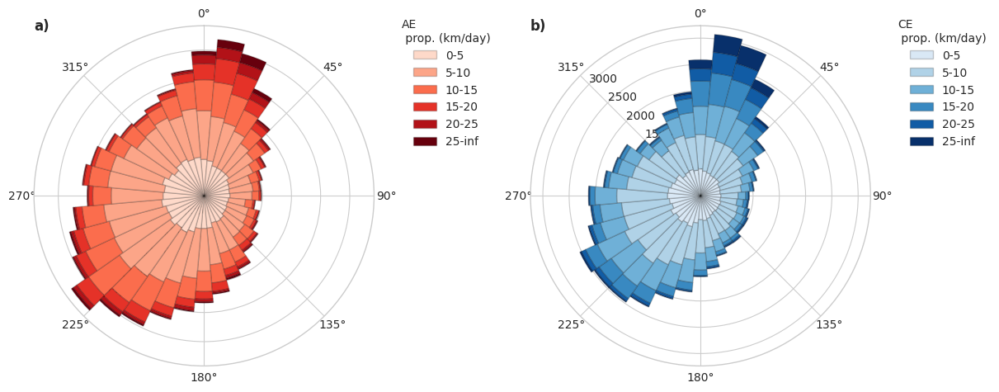

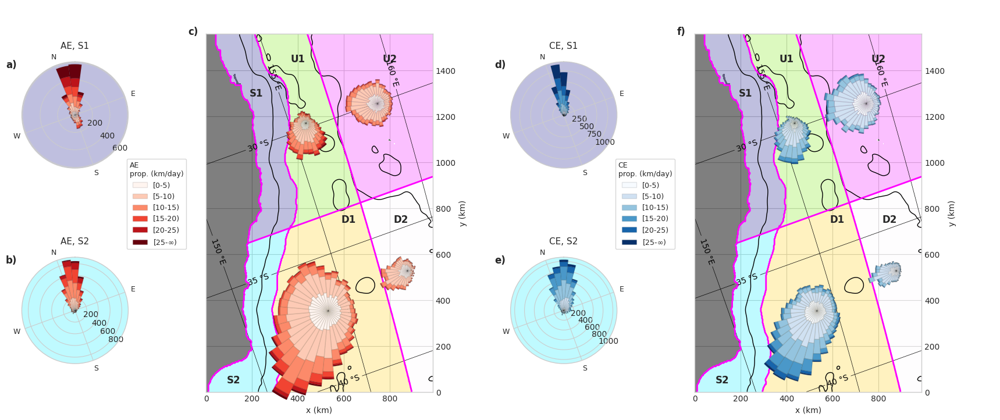

In [6]:
res_cols = primary.columns[primary.columns.str.contains('residual')]
pairs = [
    (col, col.replace('_residual_east_ms', '_residual_north_ms'))
    for col in res_cols
    if col.endswith('_residual_east_ms')
]

for x_lab, y_lab in pairs:
    print(x_lab[:-8])

    x, y = primary[x_lab], primary[y_lab]
    paired_rose(primary.copy(), x, y)

    mag, theta = xy_to_distance_direction(x, y)
    
    KM_DAY_TO_M_S = 1000.0 / 86400.0
    df = primary.copy()
    df['mag'] = mag/KM_DAY_TO_M_S
    df['theta'] = theta
    # print(x_lab[:-8])
    tilt.rose_plot(df, grid=grid, mag='mag', theta='theta',
                   mag_bins=(0, 5, 10, 15, 20, 25, np.inf), legend_title='prop. (km/day)')
    # tilt.rose_plot(df, grid=grid)

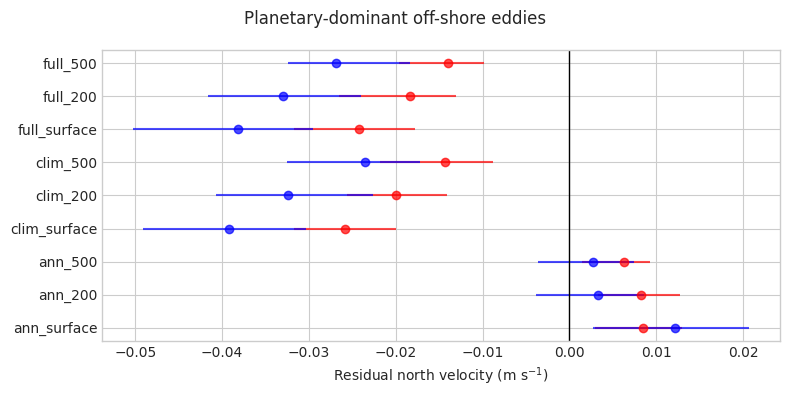

In [22]:
df = primary[primary.Region.isin(['U1', 'U2', 'D1', 'D2'])].copy()
df = df.loc[df['topo_plan_ratio'] < 0].copy() 

summary = propagation_summary(df, n_boot=5000, vec='north')
# display(summary)

plot = summary[summary['column'].str.contains('residual')].copy()
plot['method'] = plot['column'].str.replace('_residual_north_ms', '', regex=False)
fig, ax = plt.subplots(figsize=(8, 4), sharey=True)
for (cyc, part) in plot.groupby('Cyc'):
    y = np.arange(len(part))
    ax.errorbar(part['median'], y,
                xerr=[part['median']-part['ci_low'],
                      part['ci_high']-part['median']],
                fmt='o', color='r' if cyc=='AE' else 'b', alpha=.7)
ax.axvline(0, color='k', lw=1)
ax.set(yticks=y, yticklabels=part['method'], xlabel='Residual north velocity (m s$^{-1}$)')
fig.suptitle('Planetary-dominant off-shore eddies')
plt.tight_layout()

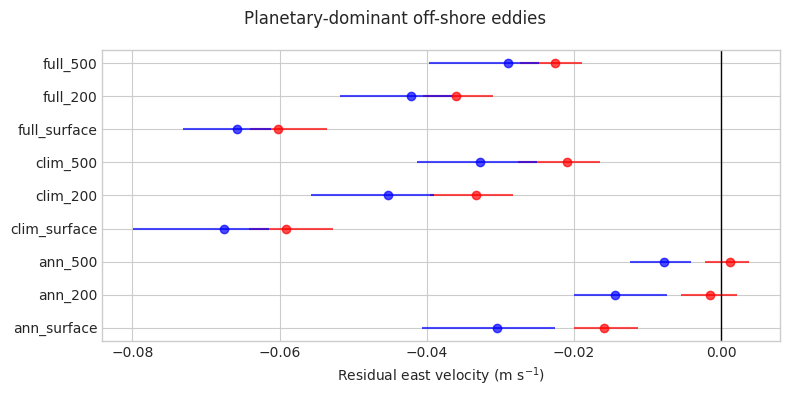

In [23]:
df = primary[primary.Region.isin(['U1', 'U2', 'D1', 'D2'])].copy()
df = df.loc[df['topo_plan_ratio'] < 0].copy() 

summary = propagation_summary(df, n_boot=5000, vec='east')
# display(summary)

plot = summary[summary['column'].str.contains('residual')].copy()
plot['method'] = plot['column'].str.replace('_residual_east_ms', '', regex=False)
fig, ax = plt.subplots(figsize=(8, 4), sharey=True)
for (cyc, part) in plot.groupby('Cyc'):
    y = np.arange(len(part))
    ax.errorbar(part['median'], y,
                xerr=[part['median']-part['ci_low'],
                      part['ci_high']-part['median']],
                fmt='o', color='r' if cyc=='AE' else 'b', alpha=.7)
ax.axvline(0, color='k', lw=1)
ax.set(yticks=y, yticklabels=part['method'], xlabel='Residual east velocity (m s$^{-1}$)')
fig.suptitle('Planetary-dominant off-shore eddies')
plt.tight_layout()

## 4. Vorticity-budget consistency check

For meridional residual velocity $v_r$, planetary-vorticity advection predicts $d w/dt \approx -\beta v_r$. This is a stronger mechanistic diagnostic than a simple association between vorticity and tilt. A budget residual centred near zero supports consistency, but does not alone establish causality.

,Cyc,column,eddies,median,ci_low,ci_high
0,AE,budget_residual_s2,1446,-1.184838e-12,-1.419019e-12,-9.311697e-13
1,CE,budget_residual_s2,1536,2.122411e-12,1.776481e-12,2.466304e-12


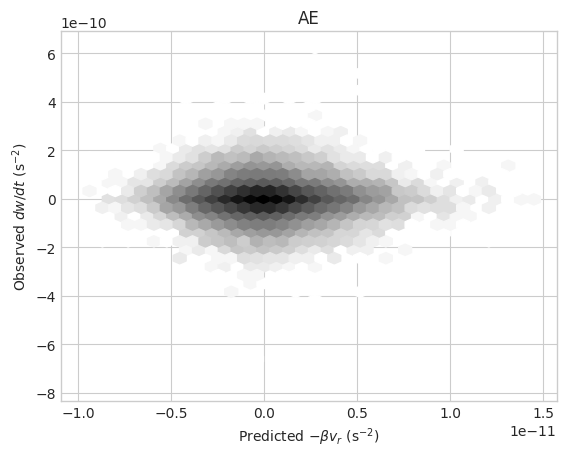

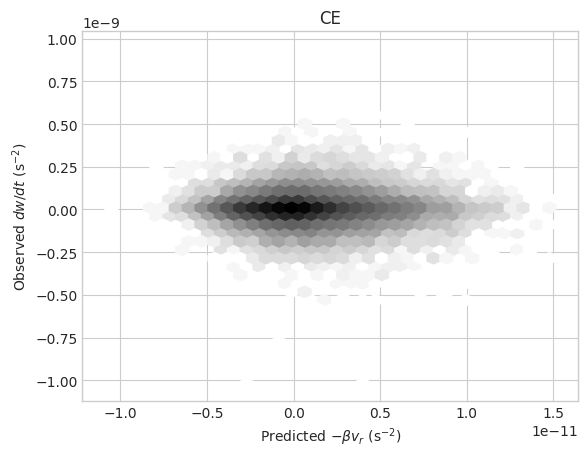

In [13]:
budget, budget_summary = vorticity_budget_summary(primary, method='clim_200')
display(budget_summary)
for cyc, part in budget.groupby('Cyc'):
    x = part['beta_advection_s2']
    y = part['dw_dt_s2']
    use = np.isfinite(x) & np.isfinite(y)
    plt.hexbin(x[use], y[use], gridsize=35, mincnt=1, bins='log', label=cyc)
    plt.xlabel(r'Predicted $-\beta v_r$ (s$^{-2}$)')
    plt.ylabel(r'Observed $dw/dt$ (s$^{-2}$)')
    plt.title(cyc)
    plt.show()

## 5. Link residual propagation to meridional tilt

Positive aligned values mean equatorward for AEs and poleward for CEs. This section tests whether the expected residual drift and the observed tilt point in the same meridional sense. Interpret day-level correlations cautiously because repeated observations from one eddy are not independent.

In [10]:
theta = np.deg2rad(primary['TiltDir'])
primary['tilt_north_km'] = primary['TiltDis'] * np.cos(theta)
primary['aligned_tilt_km'] = primary['expected_sign'] * primary['tilt_north_km']
rows = []
for method in METHODS:
    x = primary[f'{method}_aligned_residual_north_ms']
    rows.append({'method': method, 'spearman': x.corr(primary['aligned_tilt_km'], method='spearman'),
                 'n': int((x.notna() & primary['aligned_tilt_km'].notna()).sum())})
display(pd.DataFrame(rows))

,method,spearman,n
0,ann_surface,-0.024850,105621
1,ann_200,-0.043437,105621
2,ann_500,-0.051313,105621
3,clim_surface,0.041245,105621
4,clim_200,0.034358,105621
5,clim_500,0.017270,105621
6,full_surface,0.037604,105621
7,full_200,0.031146,105621
8,full_500,0.015661,105621


## 6. PV-dominance sensitivity

Require progressively stronger planetary dominance within the all-eddy cache. Thresholds here are planetary/topographic ratios of 1, 2, and 4. The polarity-specific `(w + f)` term remains in every analysis mask.

In [11]:
sensitivity = []
for ratio in [1, 2, 4]:
    part = primary[primary['topo_plan_ratio'] < -np.log(ratio)]
    result = eddy_bootstrap_ci(part, 'clim_surface_residual_north_ms', n_boot=5000)
    result['minimum_planetary_topographic_ratio'] = ratio
    sensitivity.append(result)
display(pd.concat(sensitivity, ignore_index=True))

,Cyc,column,eddies,median,ci_low,ci_high,minimum_planetary_topographic_ratio
0,AE,ann_surface_residual_north_ms,903,0.004501,-0.000339,0.008721,1
1,CE,ann_surface_residual_north_ms,706,0.016531,0.004575,0.021961,1
2,AE,ann_surface_residual_north_ms,641,0.003968,-0.002736,0.010890,2
3,CE,ann_surface_residual_north_ms,389,0.011130,-0.006348,0.019804,2
4,AE,ann_surface_residual_north_ms,370,0.009265,0.001636,0.014120,4
5,CE,ann_surface_residual_north_ms,134,0.005642,-0.008091,0.028074,4


## Interpretation checklist

The beta-effect interpretation becomes credible if: (1) AE and CE residual meridional velocities have the predicted opposite signs; (2) signs persist for instantaneous and climatological, surface and 0–500 m backgrounds; (3) the observed vorticity tendency is consistent with `-beta * residual north velocity`; (4) the signal strengthens under stricter planetary dominance; and (5) residual propagation aligns with the polarity-specific meridional tilt. Failure of one diagnostic is informative and should not be hidden by relying only on the vorticity-versus-tilt correlation.